# Bank Marketing Data Analysis

**Teste Modelagem em Python: Conjunto de Dados de Marketing Bancário Português**


Objetivo: Avaliar a capacidade do candidato em lidar com um conjunto de dados do
mundo real, realizar análise exploratória de dados (EDA), pré-processar dados, construir e avaliar um modelo de classificação e interpretar os resultados

In [120]:
import warnings
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, KBinsDiscretizer
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    roc_auc_score, precision_recall_curve, auc, f1_score, recall_score, precision_score, classification_report, confusion_matrix
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings('ignore')


In [19]:
import kagglehub

# Download
path = kagglehub.dataset_download("abdelazizsami/bank-marketing")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'bank-marketing' dataset.
Path to dataset files: /kaggle/input/bank-marketing


In [20]:
import os

# Listar os arquivos na pasta do dataset baixado para confirmar o nome correto
print("Arquivos no diretório:", os.listdir(path))

# Definir o caminho correto do arquivo (geralmente 'bank-full.csv' ou similar)
csv_path = os.path.join(path, 'bank-full.csv')

# Verificar se o arquivo CSV existe e carregá-lo corretamente com recuo adequado
if os.path.exists(csv_path):
    # Se o arquivo tiver outro nome, o print acima ajudará a identificar.
    df = pd.read_csv(csv_path, delimiter=';')
    display(df.head())
else:
    print(f"Arquivo não encontrado no caminho: {csv_path}")

Arquivos no diretório: ['bank.csv', 'bank-names.txt', 'bank-full.csv']


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [60]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


In [61]:
# Descrição das colunas
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


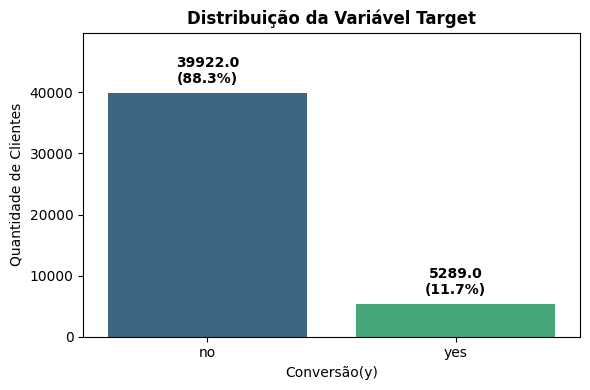

In [144]:
import matplotlib.pyplot as plt
import seaborn as sns

# Plot da variável target
plt.figure(figsize=(6, 4))
total = len(df)

ax = sns.countplot(x='y', data=df, palette='viridis', hue='y', legend=False)
plt.title('Distribuição da Variável Target', fontsize=12, fontweight='bold')
plt.xlabel('Conversão(y)')
plt.ylabel('Quantidade de Clientes')

# Rótulos
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        percentage = f'{100 * height / total:.1f}%'
        ax.annotate(f'{height}\n({percentage})',
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 5),
                    textcoords='offset points')

plt.ylim(0, total * 1.1)
plt.tight_layout()
plt.show()

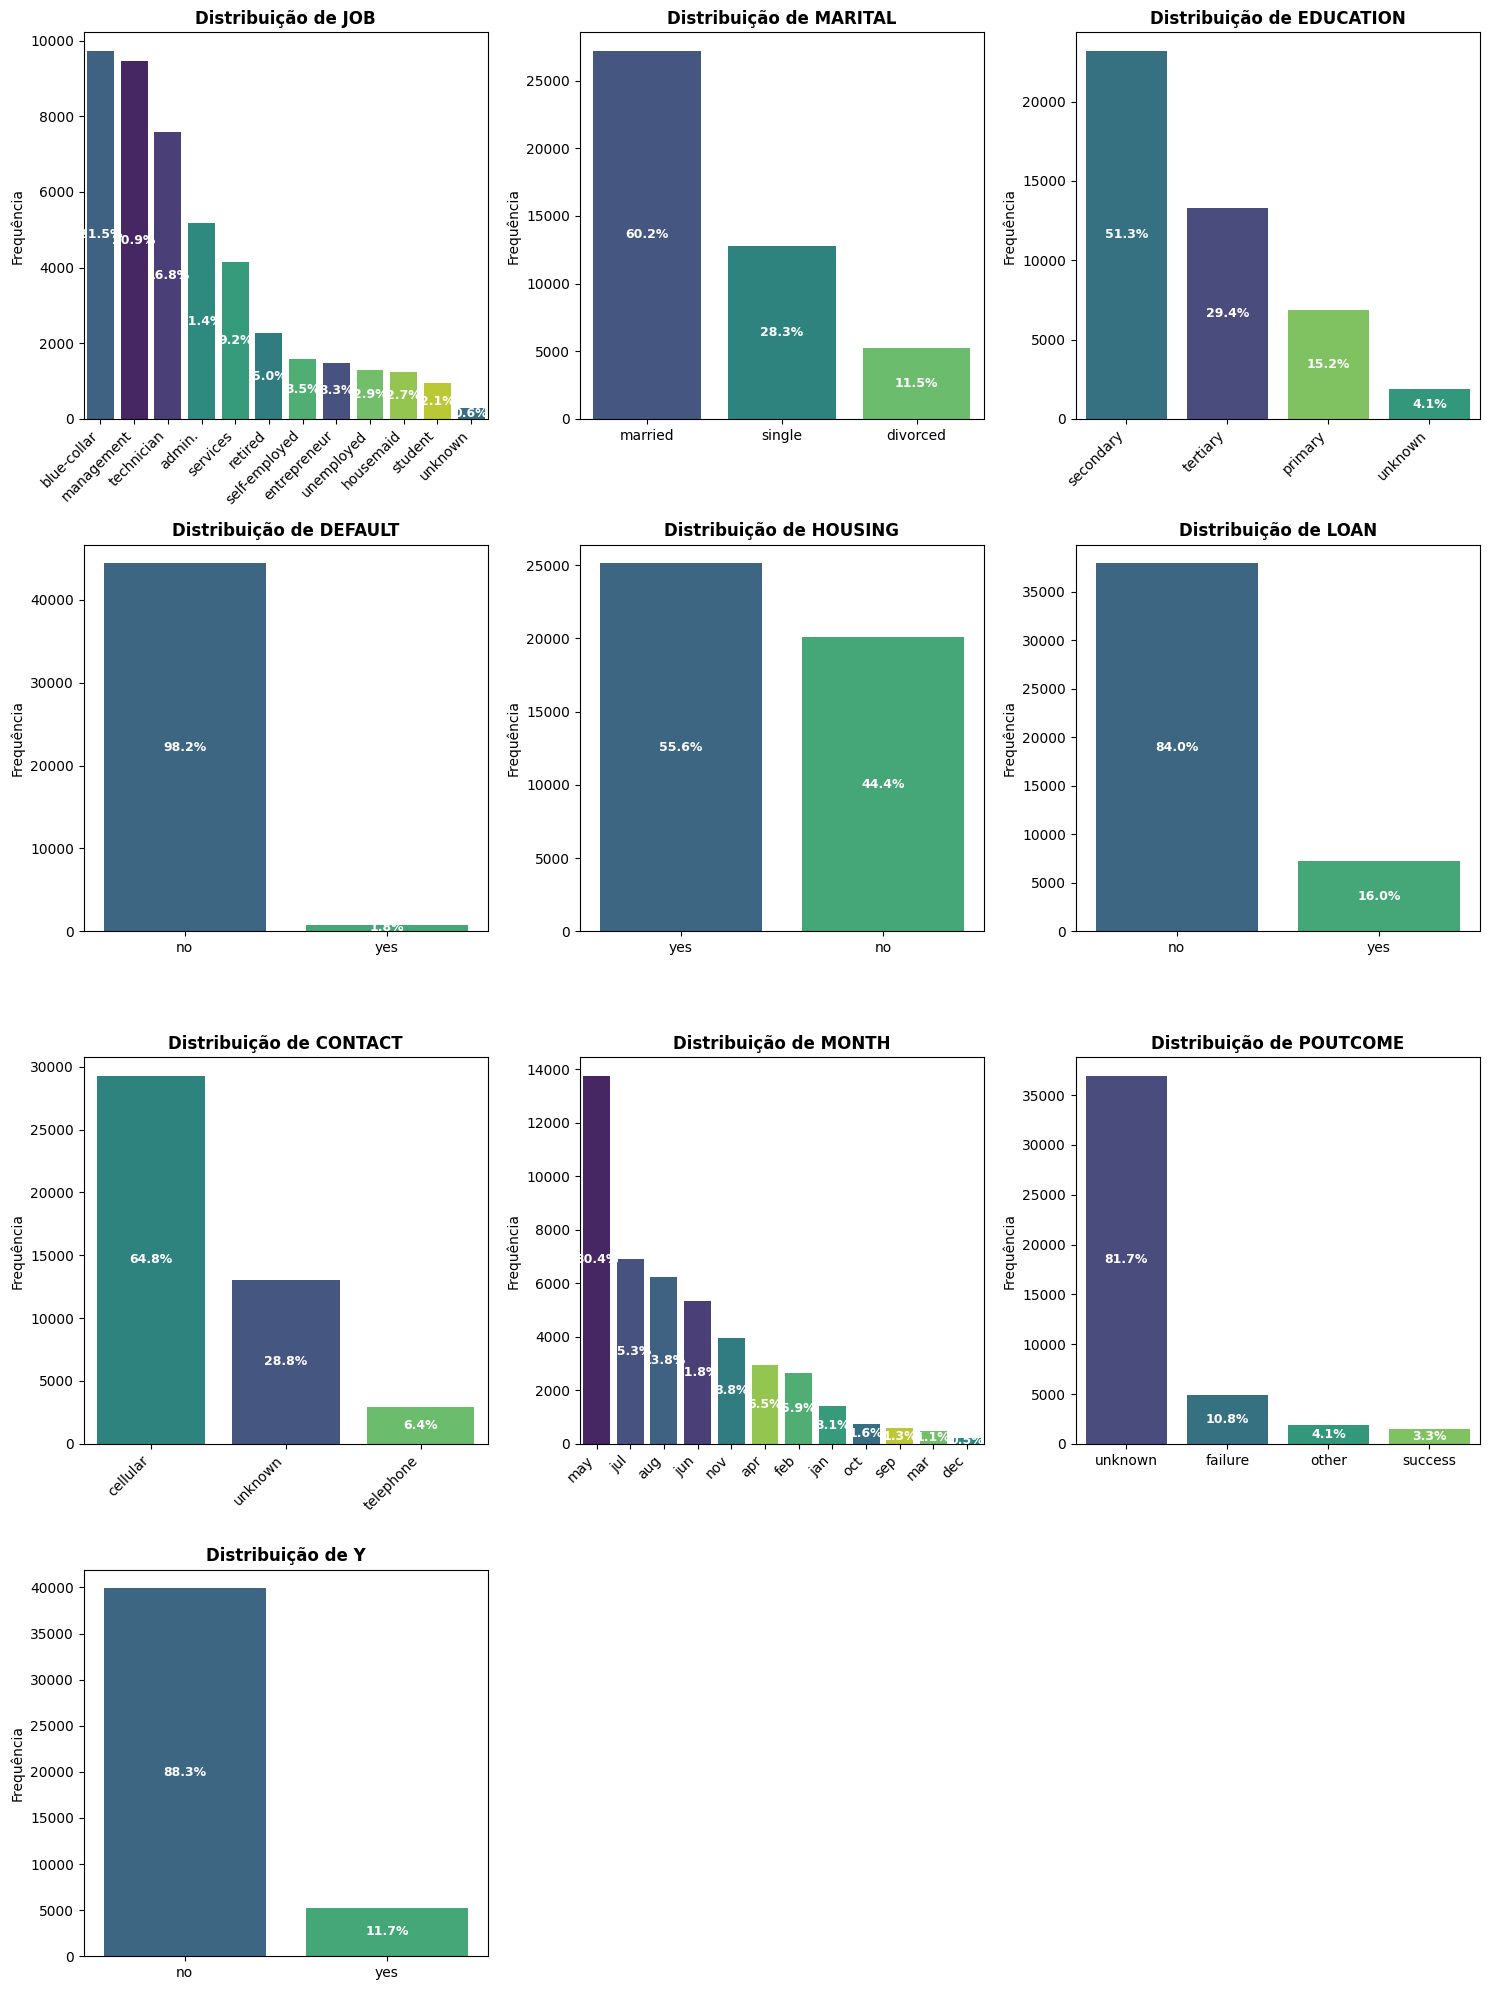

In [87]:
import matplotlib.pyplot as plt
import seaborn as sns

# Selecionar colunas categóricas
cat_cols = df.select_dtypes(include=['object']).columns

# Configurar o grid de subplots dinamicamente
num_plots = len(cat_cols)
n_cols_grid = 3
n_rows_grid = (num_plots + n_cols_grid - 1) // n_cols_grid

fig, axes = plt.subplots(n_rows_grid, n_cols_grid, figsize=(15, 5 * n_rows_grid))
axes = axes.flatten()

total_rows = len(df)

for idx, col in enumerate(cat_cols):
    order = df[col].value_counts().index
    ax = sns.countplot(data=df, x=col, order=order, ax=axes[idx], palette='viridis', hue=col, legend=False)
    axes[idx].set_title(f'Distribuição de {col.upper()}', fontsize=12, fontweight='bold')
    axes[idx].set_xlabel('')
    axes[idx].set_ylabel('Frequência')

    # Percentual dentro de cada coluna
    for p in ax.patches:
        height = p.get_height()
        if height > 0:
            percentage = f'{100 * height / total_rows:.1f}%'
            ax.annotate(percentage,
                        (p.get_x() + p.get_width() / 2., height / 2.),
                        ha='center', va='center',
                        color='white',
                        fontsize=9,
                        fontweight='bold')

    if len(order) > 4 or df[col].astype(str).str.len().max() > 8:
        axes[idx].set_xticklabels(axes[idx].get_xticklabels(), rotation=45, ha='right')

# Esconder subplots vazios
for idx in range(num_plots, len(axes)):
    fig.delaxes(axes[idx])

plt.tight_layout()
plt.show()

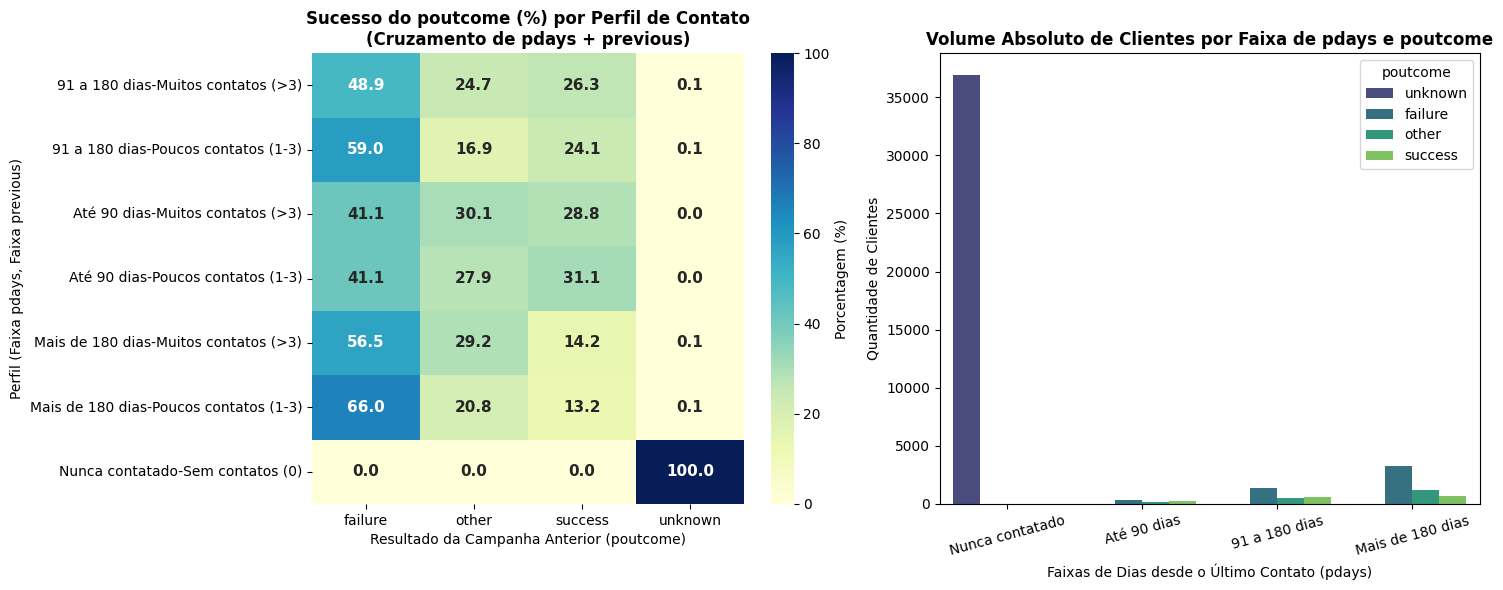

In [135]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Criar faixas categóricas para pdays e previous
df_cruzado = df.copy()

# 1. Segmentação de pdays (onde -1 significa que o cliente nunca foi contatado antes)
conditions_pdays = [
    (df_cruzado['pdays'] == -1),
    (df_cruzado['pdays'] > 0) & (df_cruzado['pdays'] <= 90),
    (df_cruzado['pdays'] > 90) & (df_cruzado['pdays'] <= 180),
    (df_cruzado['pdays'] > 180)
]
choices_pdays = ['Nunca contatado', 'Até 90 dias', '91 a 180 dias', 'Mais de 180 dias']
df_cruzado['Faixa pdays'] = np.select(conditions_pdays, choices_pdays, default='Outros')

# 2. Segmentação de previous (contatos anteriores antes desta campanha)
conditions_prev = [
    (df_cruzado['previous'] == 0),
    (df_cruzado['previous'] >= 1) & (df_cruzado['previous'] <= 3),
    (df_cruzado['previous'] > 3)
]
choices_prev = ['Sem contatos (0)', 'Poucos contatos (1-3)', 'Muitos contatos (>3)']
df_cruzado['Faixa previous'] = np.select(conditions_prev, choices_prev, default='Outros')

# 3. Criar a matriz de frequência cruzada
pivot_table = pd.crosstab(
    index=[df_cruzado['Faixa pdays'], df_cruzado['Faixa previous']],
    columns=df_cruzado['poutcome'],
    normalize='index'
) * 100

# PLOT
plt.figure(figsize=(15, 6))

# Gráfico 1: Heatmap de Frequência Cruzada Proporcional (% do Resultado da Campanha Anterior por Perfil)
plt.subplot(1, 2, 1)
sns.heatmap(pivot_table, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Porcentagem (%)'}, annot_kws={'weight': 'bold', 'size': 11})
plt.title('Sucesso do poutcome (%) por Perfil de Contato\n(Cruzamento de pdays + previous)', fontsize=12, fontweight='bold')
plt.xlabel('Resultado da Campanha Anterior (poutcome)', fontsize=10)
plt.ylabel('Perfil (Faixa pdays, Faixa previous)', fontsize=10)

# Gráfico 2: Contagem absoluta dos cruzamentos
plt.subplot(1, 2, 2)
order_pdays = ['Nunca contatado', 'Até 90 dias', '91 a 180 dias', 'Mais de 180 dias']
sns.countplot(data=df_cruzado, x='Faixa pdays', hue='poutcome', order=order_pdays, palette='viridis')
plt.title('Volume de Clientes por Faixa de pdays e poutcome', fontsize=12, fontweight='bold')
plt.xlabel('Faixas de Dias desde o Último Contato (pdays)', fontsize=10)
plt.ylabel('Quantidade de Clientes', fontsize=10)
plt.xticks(rotation=15)
plt.legend(title='poutcome')

plt.tight_layout()
plt.show()

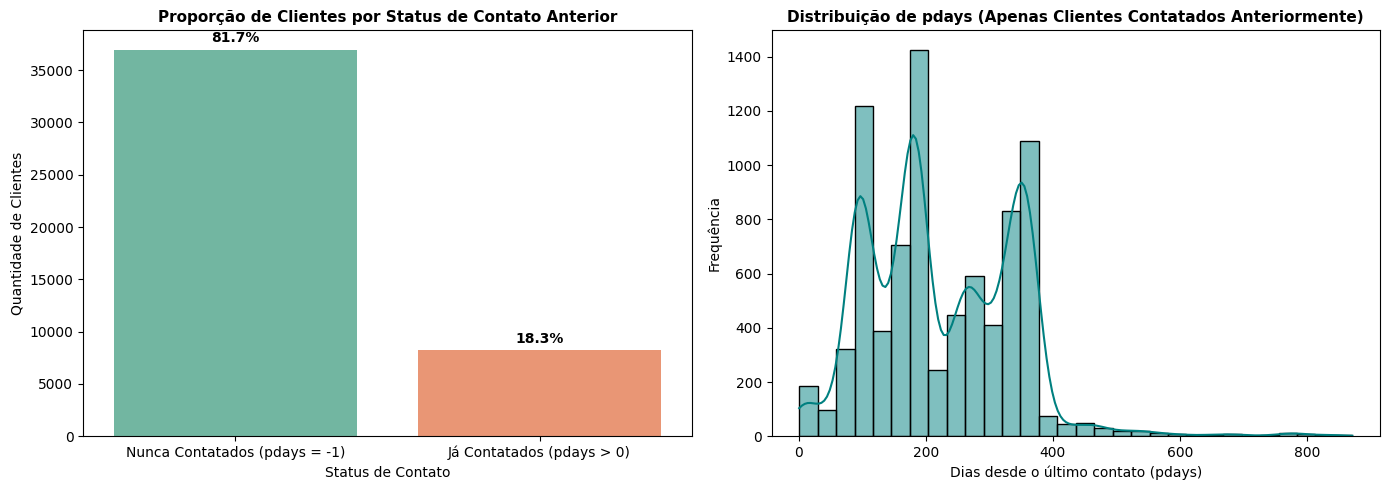

In [141]:
import matplotlib.pyplot as plt
import seaborn as sns

# Criando a figura de análise da distribuição da variável 'pdays'
plt.figure(figsize=(14, 5))

# Subplot 1: Visão Geral - Clientes Contatados vs Nunca Contatados
plt.subplot(1, 2, 1)
is_never_contacted = (df['pdays'] == -1).map({True: 'Nunca Contatados (pdays = -1)', False: 'Já Contatados (pdays > 0)'})
total = len(df)
ax = sns.countplot(x=is_never_contacted, palette='Set2', hue=is_never_contacted, legend=False)
plt.title('Proporção de Clientes por Status de Contato Anterior', fontsize=11, fontweight='bold')
plt.xlabel('Status de Contato')
plt.ylabel('Quantidade de Clientes')

# Adicionando rótulos com porcentagens no topo das barras
for p in ax.patches:
    height = p.get_height()
    if height > 0:
        percentage = f'{100 * height / total:.1f}%'
        ax.annotate(percentage,
                    (p.get_x() + p.get_width() / 2., height),
                    ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 3),
                    textcoords='offset points')

# Subplot 2: Histograma de distribuição de dias apenas para quem foi contatado (pdays > 0)
plt.subplot(1, 2, 2)
df_contatados = df[df['pdays'] > 0]
sns.histplot(data=df_contatados, x='pdays', kde=True, color='teal', bins=30)
plt.title('Distribuição de pdays (Apenas Clientes Contatados Anteriormente)', fontsize=11, fontweight='bold')
plt.xlabel('Dias desde o último contato (pdays)')
plt.ylabel('Frequência')

plt.tight_layout()
plt.show()

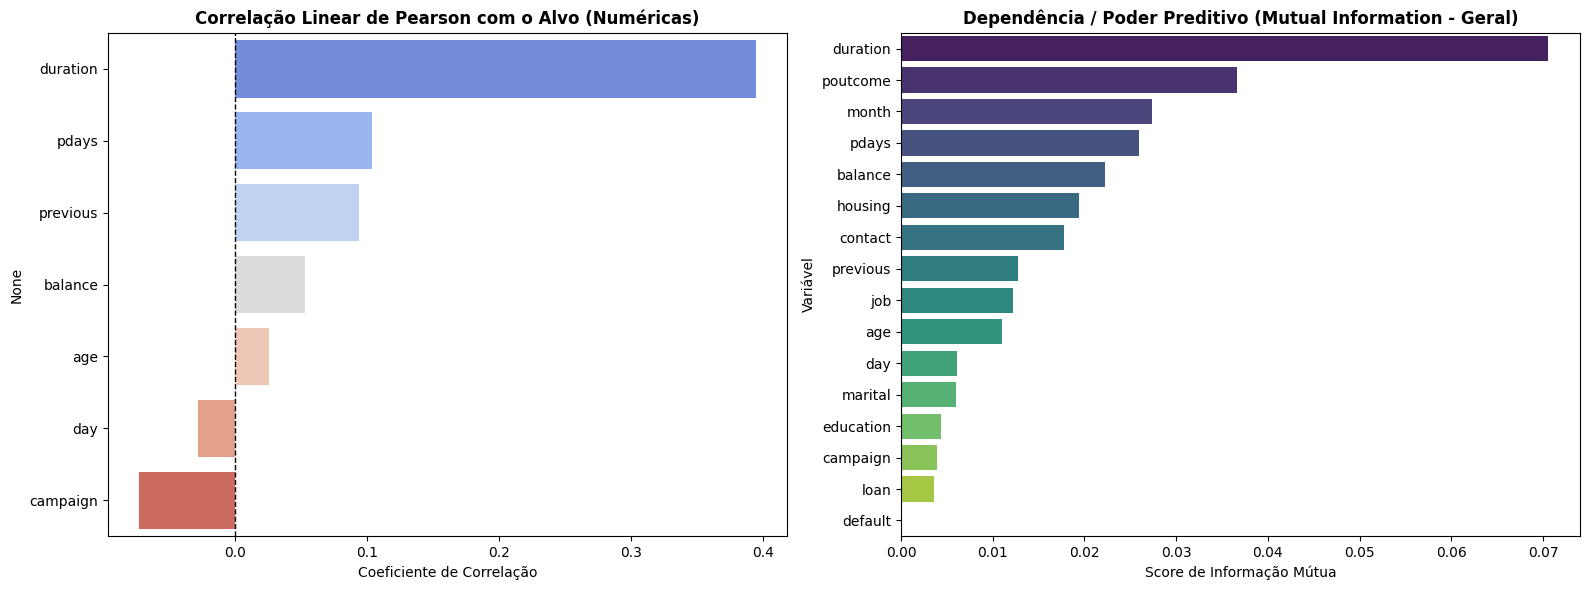

=== CORRELAÇÃO LINEAR (VARIÁVEIS NUMÉRICAS) ===
          Correlação com y
duration            0.3945
pdays               0.1036
previous            0.0932
balance             0.0528
age                 0.0252
day                -0.0283
campaign           -0.0732

=== DEPENDÊNCIA NÃO-LINEAR / ASSOCIAÇÃO (INFORMÇÃO MÚTUA - TOP 10) ===
Variável  Informação Mútua
duration          0.070507
poutcome          0.036672
   month          0.027404
   pdays          0.025954
 balance          0.022288
 housing          0.019413
 contact          0.017775
previous          0.012734
     job          0.012238
     age          0.011020


In [88]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif

# 1. Preparar os dados temporariamente (alvo binário)
df_temp = df.copy()
df_temp['target_bin'] = df_temp['y'].map({'yes': 1, 'no': 0})

# Subplot 1 - Correlação Linear para Variáveis Numéricas
num_cols = df_temp.select_dtypes(include=[np.number]).columns.drop('target_bin')
correlacoes_num = df_temp[num_cols].corrwith(df_temp['target_bin']).sort_values(ascending=False)

# Subplot 2: Associação via Informação Mútua para Todas as Variáveis ---
# Conversão de variáveis categóricas para códigos numéricos para calcular o Mutual Info
X_mi = df_temp.drop(columns=['y', 'target_bin']).copy()
for col in X_mi.select_dtypes(include=['object']).columns:
    X_mi[col] = X_mi[col].astype('category').cat.codes

mi_scores = mutual_info_classif(X_mi, df_temp['target_bin'], random_state=42)
df_mi = pd.DataFrame({'Variável': X_mi.columns, 'Informação Mútua': mi_scores})
df_mi = df_mi.sort_values(by='Informação Mútua', ascending=False)

# Plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot 1: Correlação Linear (Numéricas)
sns.barplot(x=correlacoes_num.values, y=correlacoes_num.index, ax=axes[0], palette='coolwarm', hue=correlacoes_num.index, legend=False)
axes[0].set_title('Correlação Linear de Pearson com o Alvo (Numéricas)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Coeficiente de Correlação')
axes[0].axvline(0, color='black', linestyle='--', linewidth=1)

# Plot 2: Informação Mútua (Todas as Variáveis)
sns.barplot(x='Informação Mútua', y='Variável', data=df_mi, ax=axes[1], palette='viridis', hue='Variável', legend=False)
axes[1].set_title('Dependência / Poder Preditivo (Mutual Information - Geral)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Score de Informação Mútua')

plt.tight_layout()
plt.show()

# Mostrar tabelas com os dados resumidos
print("=== CORRELAÇÃO LINEAR (VARIÁVEIS NUMÉRICAS) ===")
print(correlacoes_num.to_frame(name='Correlação com y').round(4))
print("\n=== DEPENDÊNCIA NÃO-LINEAR / ASSOCIAÇÃO (INFORMÇÃO MÚTUA - TOP 10) ===")
print(df_mi.head(10).to_string(index=False))

In [158]:
# =============================================================================
# 3. PRÉ-PROCESSAMENTO & PIPELINE DE TRANSFORMAÇÃO
# =============================================================================
def criar_preprocessadores():
    """
    Estratégia:
    1. Preprocessador Linear (Regressão Logística): Discretiza 'pdays' via KBinsDiscretizer
       em faixas temporais para evitar distorção matemática do código -1 em modelos lineares.
    2. Preprocessador de Árvores (Random Forest / XGBoost): Mantém 'pdays' contínuo (com StandardScaler),
       pois árvores realizam splits nativos no valor -1 sem perda de informação.

    """
    num_cols_gerais = ['age', 'balance', 'day', 'duration', 'campaign', 'previous']
    cat_cols = ['job', 'marital', 'education', 'housing', 'loan', 'contact', 'month', 'poutcome']

    # Preprocessador para Modelos Lineares (pdays Binned em faixas)
    preproc_linear = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), num_cols_gerais),
            ('pdays_binned', KBinsDiscretizer(n_bins=4, encode='onehot-dense', strategy='uniform'), ['pdays']),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
        ]
    )

    # Preprocessador para Modelos de Árvore (pdays Contínuo)
    num_cols_tree = num_cols_gerais + ['pdays']
    preproc_tree = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), num_cols_tree),
            ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols)
        ]
    )

    return preproc_linear, preproc_tree


In [159]:
# =============================================================================
# 4. CONSTRUÇÃO & OTIMIZAÇÃO DE MODELOS (HYPERPARAMETER TUNING)
# =============================================================================
def treinar_modelos(X_train, y_train, random_state=42):
    """
    Treina cada modelo associado ao pipeline de pré-processamento específico.
    Estratégia de balanceamento de classes cost-sensitive.
    """
    print("=" * 75)
    print("ETAPA 3 & 4: CONSTRUÇÃO DOS MODELOS COM PIPELINE")
    print("=" * 75)

    preproc_linear, preproc_tree = criar_preprocessadores()

    # 1. Regressão Logística -> Usa Preprocessador Linear (Discretização de pdays)
    pipe_lr = ImbPipeline([
        ('preproc', preproc_linear),
        ('clf', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=random_state))
    ])
    pipe_lr.fit(X_train, y_train)
    print("-> Regressão Logística (Ramo Linear: pdays Discretizado via KBinsDiscretizer)")

    # 2. Random Forest -> Usa Preprocessador de Árvore (pdays Contínuo)
    pipe_rf = ImbPipeline([
        ('preproc', preproc_tree),
        ('clf', RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=random_state))
    ])
    pipe_rf.fit(X_train, y_train)
    print("-> Random Forest (Ramo Árvore: pdays Contínuo com Split Nativo)")

    # 3. XGBoost + scale_pos_weight -> Usa Preprocessador de Árvore (pdays Contínuo + scale_pos_weight)
    ratio_desbalanceamento = (y_train == 0).sum() / (y_train == 1).sum()
    print(f"   [XGBoost] scale_pos_weight calculado automaticamente: {ratio_desbalanceamento:.2f}")

    pipe_xgb = ImbPipeline([
        ('preproc', preproc_tree),
        ('clf', XGBClassifier(scale_pos_weight=ratio_desbalanceamento, eval_metric='logloss', random_state=random_state))
    ])

    param_grid_xgb = {
        'clf__n_estimators': [50, 100],
        'clf__max_depth': [3, 5],
        'clf__learning_rate': [0.05, 0.1]
    }

    grid_xgb = GridSearchCV(pipe_xgb, param_grid_xgb, cv=3, scoring='roc_auc', n_jobs=-1)
    grid_xgb.fit(X_train, y_train)
    print(f"-> XGBoost (scale_pos_weight={ratio_desbalanceamento:.2f}) (Ramo Árvore Otimizado | CV ROC-AUC: {grid_xgb.best_score_:.4f})")
    print("=" * 75 + "\n")

    modelos = {
        'Regressão Logística': pipe_lr,
        'Random Forest': pipe_rf,
        'XGBoost': grid_xgb.best_estimator_
    }
    return modelos

In [160]:
# =============================================================================
# 5. AVALIAÇÃO DO MODELO & MÉTRICAS EXPLICATIVAS
# =============================================================================
def avaliar_modelos_teste(modelos, X_test, y_test, custo_fp=15, custo_fn=150):
    """
    Avalia os modelos no conjunto de teste final e calcula o impacto financeiro.
    custo_fp = 15 ---> Custo do Falso Positivo --> custo da operação (tempo atendente)
    custo_fn = 150 ---> Custo do Falso Negativo --> custo de contrato perdido (prejuizo)

    """
    print("=" * 75)
    print("ETAPA 5: AVALIAÇÃO NO CONJUNTO DE TESTE")
    print("=" * 75)

    resultados = []

    for nome, model in modelos.items():
        y_pred = model.predict(X_test)
        y_prob = model.predict_proba(X_test)[:, 1]

        roc = roc_auc_score(y_test, y_prob)
        prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_prob)
        pr_auc = auc(rec_curve, prec_curve)
        f1 = f1_score(y_test, y_pred)
        rec = recall_score(y_test, y_pred)
        prec = precision_score(y_test, y_pred, zero_division=0)

        # Custo financeiro de negócio
        tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()
        custo_total = (fp * custo_fp) + (fn * custo_fn)

        resultados.append({
            'Modelo': nome,
            'ROC-AUC': round(roc, 4),
            'PR-AUC': round(pr_auc, 4),
            'F1-Score': round(f1, 4),
            'Recall': round(rec, 4),
            'Precisão': round(prec, 4),
            'Custo Negócio (R$)': custo_total
        })

    df_res = pd.DataFrame(resultados).sort_values(by='PR-AUC', ascending=False)
    print(df_res.to_string(index=False))
    print("=" * 75 + "\n")
    return df_res

In [161]:
def plotar_avaliacao_comparativa(modelos, X_test, y_test, custo_fp=15, custo_fn=150):
    """
    Gera painéis visuais com as matrizes de confusão de cada modelo,
    exibindo a contagem absoluta, o percentual correspondente e o custo financeiro associado
    a cada quadrante de decisão.

    """
    import matplotlib.pyplot as plt
    import seaborn as sns
    import numpy as np
    from sklearn.metrics import confusion_matrix

    num_modelos = len(modelos)

    fig, axes = plt.subplots(1, num_modelos, figsize=(4.5 * num_modelos, 5))
    if num_modelos == 1:
        axes = [axes]

    # Cores
    cmaps = ['Blues', 'Oranges', 'Greens', 'Purples', 'Reds']

    for idx, (nome, model) in enumerate(modelos.items()):
        y_pred = model.predict(X_test)
        cm = confusion_matrix(y_test, y_pred)

        # Extrair os quadrantes: tn, fp, fn, tp
        tn, fp, fn, tp = cm.ravel()

        # Calcular os custos segmentados por célula
        custo_tn = 0.0
        custo_fp_celula = fp * custo_fp
        custo_fn_celula = fn * custo_fn
        custo_tp = 0.0

        # Calcular percentuais em relação aos totais reais de cada linha
        cm_percent = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100

        # Montar os rótulos internos combinando Valor Absoluto, Percentual Real e Custo Financeiro em R$
        labels = np.array([[
            f"{tn}\n({cm_percent[0,0]:.1f}%)\nR$ {custo_tn:,.2f}",
            f"{fp}\n({cm_percent[0,1]:.1f}%)\nR$ {custo_fp_celula:,.2f}"
        ], [
            f"{fn}\n({cm_percent[1,0]:.1f}%)\nR$ {custo_fn_celula:,.2f}",
            f"{tp}\n({cm_percent[1,1]:.1f}%)\nR$ {custo_tp:,.2f}"
        ]])

        # Plotar cada matriz
        ax_cm = axes[idx]
        cmap_sel = cmaps[idx % len(cmaps)]

        sns.heatmap(cm, annot=labels, fmt='', cmap=cmap_sel, ax=ax_cm, cbar=False, square=True,
                    annot_kws={'size': 10, 'weight': 'bold'})

        # Custo consolidado deste modelo para colocar no título
        custo_total_modelo = custo_fp_celula + custo_fn_celula
        ax_cm.set_title(f'{nome}\nCusto Total: R$ {custo_total_modelo:,.2f}', fontsize=10, fontweight='bold', pad=10)
        ax_cm.set_xlabel('Predito', fontsize=9)
        ax_cm.set_ylabel('Real', fontsize=9)
        ax_cm.set_xticklabels(['Não (0)', 'Sim (1)'], fontsize=9)
        ax_cm.set_yticklabels(['Não (0)', 'Sim (1)'], fontsize=9, rotation=0)

    plt.tight_layout()
    plt.show()

In [162]:
# =============================================================================
# 6. INTERPRETAÇÃO, FEATURE IMPORTANCE
# =============================================================================
def extrair_insights_modelo(best_model, num_cols, cat_cols):
    """
    Extrai a importância das variáveis.
    """
    print("=" * 75)
    print("ETAPA 6: INTERPRETAÇÃO E INSIGHTS ACIONÁVEIS")
    print("=" * 75)

    clf = best_model.named_steps['clf']
    preproc = best_model.named_steps['preproc']

    # Nomes das colunas pós-encoder
    cat_encoder = preproc.named_transformers_['cat']
    encoded_cat_cols = list(cat_encoder.get_feature_names_out(cat_cols))
    feature_names = num_cols + encoded_cat_cols

    if hasattr(clf, 'feature_importances_'):
        importances = clf.feature_importances_
        df_feat = pd.DataFrame({'Atributo': feature_names, 'Importancia': importances})
        df_feat = df_feat.sort_values(by='Importancia', ascending=False).head(8)

        print("Top 8 Atributos Mais Influentes na Decisão do Cliente:")
        for idx, row in df_feat.reset_index(drop=True).iterrows():
            print(f"  {idx+1}. {row['Atributo']:<30} (Peso: {row['Importancia']:.4f})")

    print("=" * 75 + "\n")

In [163]:
# =============================================================================
# 7. EXEMPLO DE UTILIZAÇÃO EM PRODUÇÃO (INFERENCE PIPELINE CLASS)
# =============================================================================
class InferenceService:
    """
    Classe pronta para produção que encapsula o modelo treinado para servir previsões via API ou Batch.
    """
    def __init__(self, trained_pipeline):
        self.pipeline = trained_pipeline

    def prever_propensao_cliente(self, dados_novos_dict):
        """
        Recebe um dicionário com os dados de um cliente e retorna a probabilidade e recomendação.
        """
        df_cliente = pd.DataFrame([dados_novos_dict])
        probabilidade = float(self.pipeline.predict_proba(df_cliente)[:, 1][0])
        decisao = "Contatar Cliente (Alta Propensão)" if probabilidade >= 0.5 else "Não Contatar (Baixa Propensão)"

        return {
            'probabilidade_conversao': round(probabilidade, 4),
            'recomendacao_acao': decisao
        }

ETAPA 3 & 4: CONSTRUÇÃO DOS MODELOS COM PIPELINE
-> Regressão Logística (Ramo Linear: pdays Discretizado via KBinsDiscretizer)
-> Random Forest (Ramo Árvore: pdays Contínuo com Split Nativo)
   [XGBoost] scale_pos_weight calculado automaticamente: 7.55
-> XGBoost (scale_pos_weight=7.55) (Ramo Árvore Otimizado | CV ROC-AUC: 0.9319)

ETAPA 5: AVALIAÇÃO NO CONJUNTO DE TESTE
             Modelo  ROC-AUC  PR-AUC  F1-Score  Recall  Precisão  Custo Negócio (R$)
            XGBoost   0.9305  0.6260    0.5810  0.8800    0.4336               37290
      Random Forest   0.9271  0.6172    0.4561  0.3384    0.6992              107310
Regressão Logística   0.9094  0.5358    0.5549  0.8195    0.4194               46650



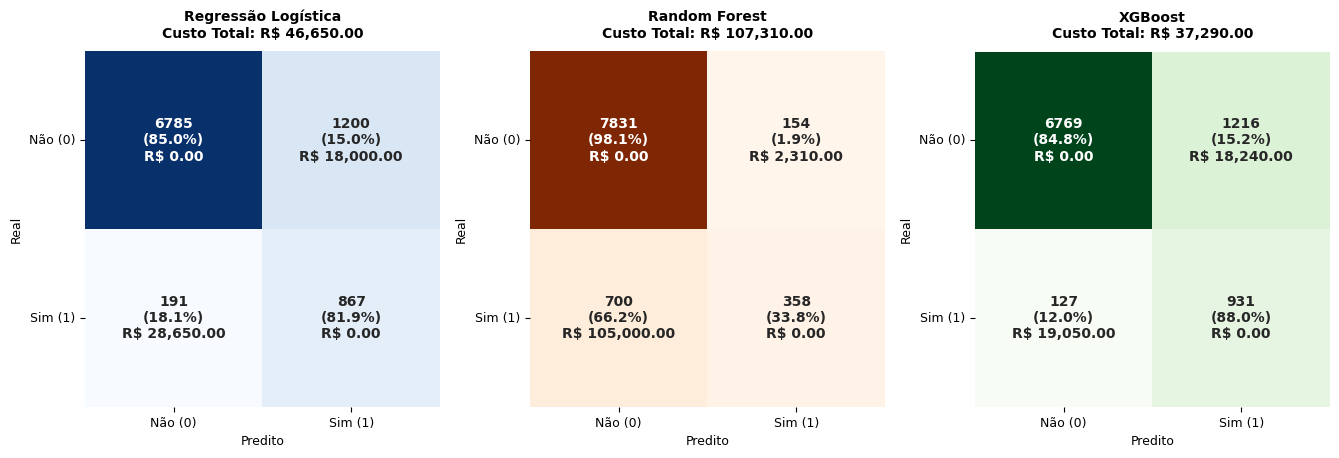

ETAPA 6: INTERPRETAÇÃO E INSIGHTS ACIONÁVEIS
Top 8 Atributos Mais Influentes na Decisão do Cliente:
  1. poutcome_success               (Peso: 0.1437)
  2. contact_unknown                (Peso: 0.1260)
  3. duration                       (Peso: 0.0706)
  4. poutcome_unknown               (Peso: 0.0645)
  5. housing_no                     (Peso: 0.0517)
  6. month_mar                      (Peso: 0.0488)
  7. month_jun                      (Peso: 0.0410)
  8. month_oct                      (Peso: 0.0378)

ETAPA 7: TESTE DE INFERÊNCIA EM PRODUÇÃO
Simulação de Inferência para Novo Cliente:
  - Probabilidade calculada: 61.56%
  - Ação recomendada:       Contatar Cliente (Alta Propensão)


In [164]:
# =============================================================================
# EXECUÇÃO
# =============================================================================
if __name__ == "__main__":
    # 1. Divisão Treino e Teste Estratificada (Mapeando o alvo para binário 0/1)
    X = df.drop(columns=['y'])
    y = df['y'].map({'yes': 1, 'no': 0})
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

    # 2. Treino e Otimização (Linear vs Árvore)
    modelos = treinar_modelos(X_train, y_train, random_state=42)

    # 3. Avaliação no Teste e Comparação Visual das Métricas e Impacto Financeiro
    df_eval = avaliar_modelos_teste(modelos, X_test, y_test)
    plotar_avaliacao_comparativa(modelos, X_test, y_test)

    # 4. Extração de Feature Importances
    best_model_name = 'XGBoost'
    best_model = modelos[best_model_name]

    # Feature Importances
    num_cols_tree = ['age', 'balance', 'day', 'duration', 'campaign', 'previous', 'pdays']
    cat_cols = ['job', 'marital', 'education','housing', 'loan', 'contact', 'month', 'poutcome']
    extrair_insights_modelo(best_model, num_cols_tree, cat_cols)

    # 5. Teste de Inferência em Produção(Simulação)
    print("=" * 75)
    print("ETAPA 7: TESTE DE INFERÊNCIA EM PRODUÇÃO")
    print("=" * 75)
    servico = InferenceService(best_model)

    novo_cliente = {
        'age': 20,
        'balance': 500.0,
        'day': 15,
        'duration': 100,
        'campaign': 1,
        'pdays': 120,
        'previous': 2,
        'job': 'management',
        'marital': 'married',
        'education': 'tertiary',
        'default': 'no',
        'housing': 'yes',
        'loan': 'yes',
        'contact': 'cellular',
        'month': 'mar',
        'poutcome': 'success'
    }

    res = servico.prever_propensao_cliente(novo_cliente)
    print("Simulação de Inferência para Novo Cliente:")
    print(f"  - Probabilidade calculada: {res['probabilidade_conversao']*100:.2f}%")
    print(f"  - Ação recomendada:       {res['recomendacao_acao']}")
    print("=" * 75)